In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats

#random.seed(42)
#np.random.seed(42)

# Principe

- On veut que la sortie $z(t)= \sum z_i R(x_i(t))$ ressemble à $f(t)$ en apprenant les $z_i$.
  $$\dfrac{dx_i}{dt} = -x_i - g \dfrac{1}{n} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + b_i z(t) + I_i$$.
- On utilise $ReLU$ comme taux de décharge, $b$ constant, $w_{i,j} \sim \mathcal{N} \left(0,\dfrac{1}{N^2} \right)$ en gardant uniquement les valeurs négatives, I avec la même valeur pour tous les neurones et $f(t) = sin(\dfrac t 2)$ comme fonction cible. 

On veut minimiser :
$$ \dfrac{1}{T} \int_{0}^{T} (z(t) - f(t))^2 dt) + \dfrac{\rho}{2} \sum z_i^2$$
$$ \iff \dfrac{1}{T} \int_{0}^{T} (z(t) - f(t))^2 dt) + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$
$$ \iff \dfrac{1}{T} \int_{0}^{T} \sum_{i,j} z_i z_j R(x_i (t)) R(x_j (t)) - 2 \sum z_j R(x_j(t)) f(t) + f^2 (t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z $$
$$\iff \dfrac{1}{T} \sum_{i,j} z_i z_j \int_{0}^{T} \langle R(x_i(t)) R(x_j (t)) \rangle - 2 \sum z_j \dfrac{1}{T}  \int_{0}^{T}R(x_ j(t)) f(t) + \dfrac{1}{T} \int_{0}^{T} f^2(t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$

En utilisant le fait que $ \displaystyle \sum_{i} a_i b_i = \langle b \rangle \displaystyle \sum_{i} a_i + \displaystyle \sum_{i} a_i ( b_i - \langle b \rangle)$ et en faisant l'approximation $ \displaystyle \sum_{i} a_i b_i = \langle b \rangle \displaystyle \sum_{i} a_i$

On pose : 
$$ c_{i,j} = \dfrac{1}{T}  \int_{0}^{T} \langle R(x_i(t))R(x_j(t)) \rangle = \langle R(x_i(t)) R(x_j(t)) \rangle $$
$$ f_i = \dfrac{1}{T} \int_{0}^{T} R(x_i(t)) f(t)dt $$

Donc on a :

$$Z^TCZ - 2 F^T Z + \dfrac{1}{T} \int_{0}^{T} f^2(t) dt + \dfrac{\rho}{2} \cdot Z^T \mathbb{I} Z$$

La dérivée par rapport à $Z$ vaut : 

$$ 2CZ - 2F + \rho Z$$

On cherche le minimum de la fonction de coût donc quand :

$$ 2CZ - 2F + \rho Z = 0$$
$$ \iff F = (C + \dfrac {\rho}{2} \mathbb{I}) Z$$
$$ Z = (C + \dfrac {\rho}{2} \mathbb{I})^{-1} F$$

-------
-  Dans un premier temps, pour trouver les $x_i$, on suppose que la procédure marche et on pose :
  $$\dfrac{dx_i}{dt} = -x_i - g \dfrac{1}{n} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + b_i f(t) + I_i$$

- Dans un second temps, on calcule $Z$ avec les $x_i$ trouvés

- Puis on regarde si $Z$ suit bien le motif voulu

# Simulation

## $1$) Calculer les $x_i$

In [2]:
"""
def f(t):
    if np.floor(t / 10) % 2 == 0:
        A = 0.2
    else:
        A = 0.3
    return A * np.sin(np.pi / 5 * t)
"""

#commencer par sin :
def f(t):
    return np.sin(np.pi * t /5)


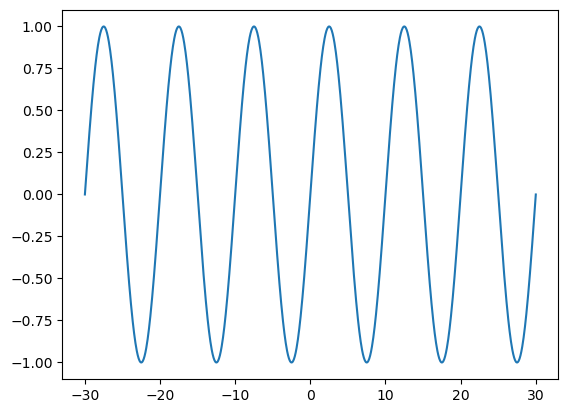

In [3]:
t_test = np.linspace(-30, 30, 1000)
Itv = [f(i) for i in t_test]
plt.plot(t_test, Itv)
plt.show()

In [4]:
n = 1000

In [5]:
i = 1

In [6]:
"""
def I(n,i):
    return np.array([i for j in range (n)])
"""

def I(n):
    return np.array([random.uniform(0,1) for i in range (n)])

In [7]:
def exemple_X(n):
    X = [random.uniform(-0.5,0.5) for i in range(n)]
    X = np.array(X)
    return X

In [8]:

def W_inhib(n):
    W = []
    w = []
    i=0
    graine = random.Random(42)
    for j in range(n):
        while i<n :
            x = graine.gauss(0,1/(np.sqrt(n)))
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W
"""

def W_pm(n):
    graine = random.Random(42)
    W = [[graine.gauss(0,1/np.sqrt(n)) for j in range (n)] for i in range (n)]
    W = np.array(W)
    return W
"""



'\n\ndef W_pm(n):\n    graine = random.Random(42)\n    W = [[graine.gauss(0,1/np.sqrt(n)) for j in range (n)] for i in range (n)]\n    W = np.array(W)\n    return W\n'

In [9]:
gamma = 0.2

In [10]:
"""
def R(X) :
    return np.maximum(X,0)
"""
"""
def R(X) :
    return np.tanh(X)
"""


def R(X,gamma) :
    return X * (1 + np.tanh(X/gamma))/2


In [11]:
def B(n) :
    graine = random.Random(42)
    B = [graine.uniform(-0.5,0.5) for i in range(n)]
    B = np.array(B)
    return B

In [12]:
g = 2
t_0 = 0
W = W_inhib(n) 
B_n = B(n)
X_0 = exemple_X(n)
h = 0.01
T = 100
I_n = I(n)

In [13]:
def deriv_X(X,g,W,B_n,t,I_n,gamma) :
    return -X+g* ( W @ R(X,gamma)) + B_n * f(t) + I_n

In [14]:
def Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,gamma):
    Images_Euler = [X_0]
    Atcd_Euler = [t_0]
    X = X_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * deriv_X(X,g,W,B_n,t,I_n,gamma) + X  
        t += h
        Images_Euler.append(X)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [15]:
def graph_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,gamma):
    Atcd_Euler,Images_Euler = Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,gamma)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler])
    plt.show()

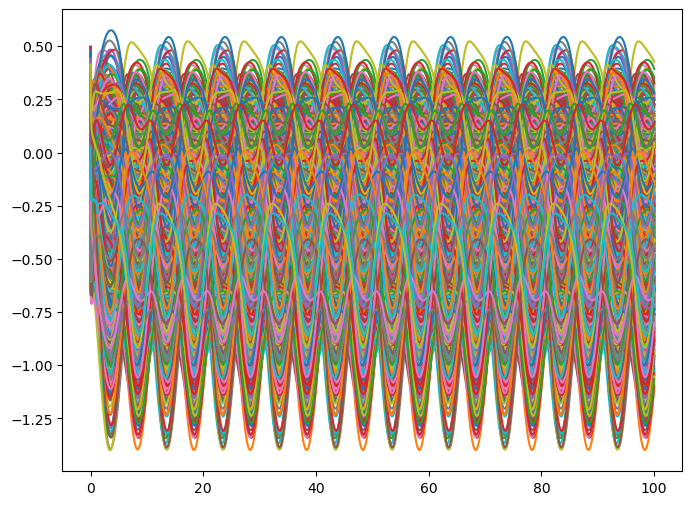

In [16]:
graph_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,gamma)

## $2$) Calculer les $z_i$

In [17]:
Atcd_Euler,Images_Euler = Euler_O1(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,gamma)

On ne veut pas prendre en compte la phase transitoire donc on ne prend pas les valeurs initiales pour calculer $C$ et $F$

In [18]:
t_stable = 10

In [19]:
def C(Images_Euler, h, t_stable):
    X = np.array(Images_Euler)
    i_depart = int(t_stable / h)

    X_stable = X[i_depart:]
    R_X = R(X_stable,gamma)

    C= (np.transpose(R_X) @ R_X) / len(R_X)

    return C 

In [20]:
def F_rectangle(Images_Euler,T,h,t_stable):
    S = []
    i_depart = int(t_stable / h)
    for j in range (len(Images_Euler[0])):
        s = 0
        t = t_stable
        for i in range (i_depart, len(Images_Euler)):
            r = h * f(t) * R(Images_Euler[i][j],gamma)
            t += h 
            s += r
        S.append(s/(T - t_stable))
    return S

In [21]:
rho = 10**(-4)
C_n = C(Images_Euler,h,t_stable)
F = F_rectangle(Images_Euler,T,h,t_stable)

In [22]:
def z(C_n,F,rho,n):
    return np.linalg.inv(C_n + rho / 2 * np.eye(n)) @ F

In [23]:
z_n = z(C_n,F,rho,n)

In [24]:
def Z(z_n,X):
    return z_n @ R(X,gamma)

In [25]:
def graph_sortie_forcé(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,z_n):
    z_sortie = [Z(z_n, X) for X in Images_Euler]
    attente = [f(t) for t in Atcd_Euler]
    
    plt.figure(figsize=(8, 5))
    plt.plot(Atcd_Euler, attente, label="f(t)")
    plt.plot(Atcd_Euler, z_sortie, label="z(t)")
    plt.legend()
    plt.show()

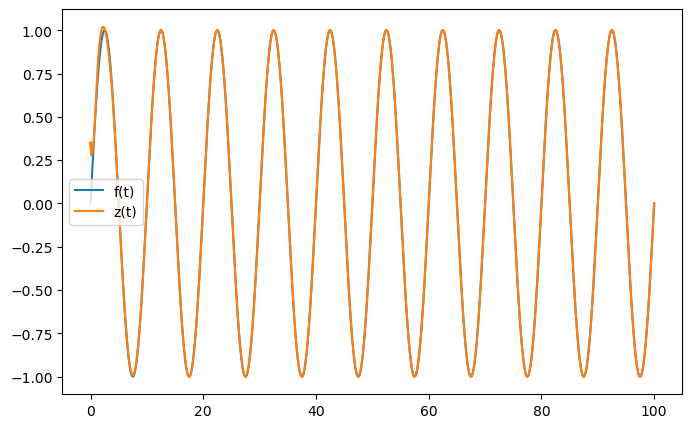

In [26]:
graph_sortie_forcé(deriv_X,t_0,X_0,h,T,g,W,B_n,I_n,z_n)

## $3$) Regarder si $z$ correspond à $f(t)$

In [27]:
def deriv_X_ac_Z(X,g,W,B_n,z_n,I_n,gamma) :
    return -X+g* ( W @ R(X,gamma)) + B_n * Z(z_n,X) + I_n

In [28]:
def Euler_O1_2(deriv_X_ac_Z,t_0,h,T,g,W,B_n,z_n,I_n,gamma):
    Images_Euler_2 = [Images_Euler[-1]]
    Atcd_Euler_2 = [t_0]
    X = Images_Euler[-1]
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * deriv_X_ac_Z(X,g,W,B_n,z_n,I_n,gamma) + X  
        t += h
        Images_Euler_2.append(X)
        Atcd_Euler_2.append(t)
    return Atcd_Euler_2,np.array(Images_Euler_2)

In [29]:
Atcd_Euler_2,Images_Euler_2 = Euler_O1_2(deriv_X_ac_Z,t_0,h,T,g,W,B_n,z_n,I_n,gamma)

In [30]:
def graph_O1_2(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n,gamma):
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler_2,[X[i] for X in Images_Euler_2])
    plt.show()

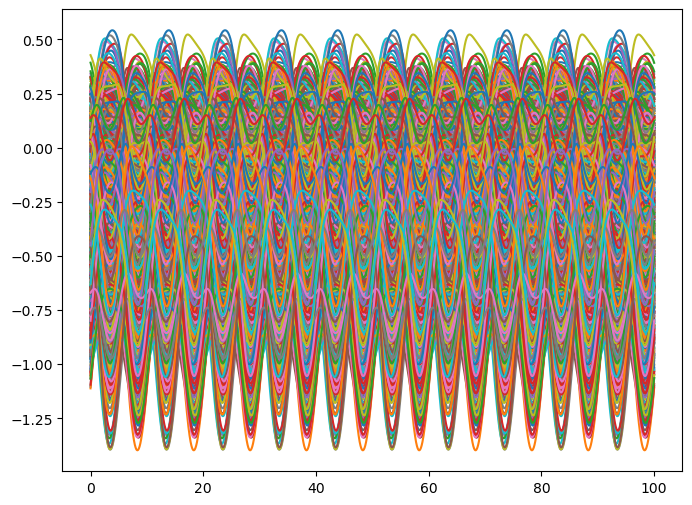

In [31]:
graph_O1_2(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n,gamma)

In [32]:
def graph_sortie(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n):
    t = np.array(Atcd_Euler_2) + T
    z_sortie = [Z(z_n, X) for X in Images_Euler_2]
    attente = [f(i) for i in t]
    
    plt.figure(figsize=(8, 5))
    plt.plot(t, attente, label="f(t)",alpha = 0.5)
    plt.plot(t, z_sortie, label="z(t)", alpha = 0.5)
    plt.legend()
    plt.savefig("sortie_ok.pdf", bbox_inches="tight")
    plt.show()


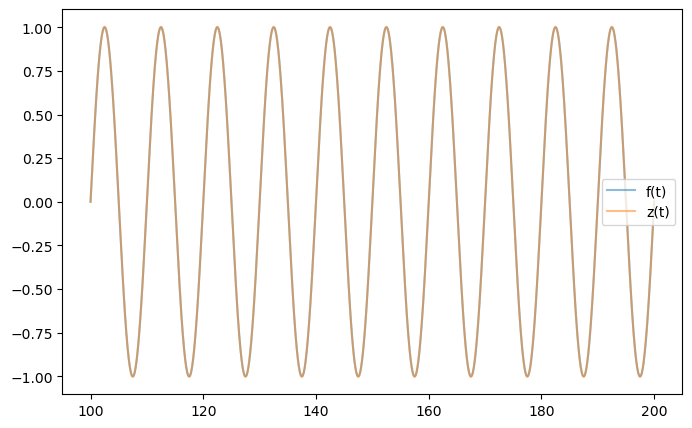

In [33]:
graph_sortie(deriv_X_ac_Z,t_0,X_0,h,T,g,W,B_n,z_n,I_n)

## Valeurs propres

On a : $$ \dfrac{d \delta x_i}{dt} = - \delta x_i + g\sum_{j=1}^{n}( w_{i,j} R'(x_j^*)\delta x_j) + b_i \sum_{j} z_j R'(x_j^*)\delta x_j (t)$$
Donc : $$ \dfrac{d \delta X}{dt} = - \delta X + gWD\delta X + BZ^TD\delta X$$
$$ \iff \dfrac{d \delta X}{dt} = (-I + gWD + BZ^TD)\delta X$$
avec $D$ la matrice diagonale où les coefficients diagonaux valent $1$ si $x_j^*>0$ et $0$ sinon (si $R$ est la fonction $ReLU$)

En posant $M = -I + gWD + BZ^TD$, on a donc :
$$ \dfrac{d \delta X}{dt} = M \delta X $$


In [34]:
def deriv_R (X,gamma):
    u = np.tanh(X / gamma)

    return (
        0.5 * (1 + u)
        + X / (2 * gamma) * (1 - u**2)
    )

In [35]:
def eq_eqb(X, W, g, B_n, z_n, I_n, gamma) :
    return -X + g * (W @ R(X,gamma)) + B_n * (z_n @ R(X,gamma)) + I_n

Prendre la moyenne des derniers $x_i$ comme point de départ pour la méthode de Newton :

In [36]:
X_ini = np.mean(Images_Euler_2[int(-20 / h):, :],axis=0)

In [37]:
"""
#relu
def D(Images_Euler_2,h):    
    X_moy = []
    for j in range (len(Images_Euler_2[0])):
        l=[]
        for i in range (int(-20 / h),0):
            l.append(Images_Euler_2[i][j])
        if np.mean(l) > 0:
            X_moy.append(1)
        else :
            X_moy.append(0)
    m_diag = np.diag(X_moy)
    return m_diag
"""

"""
def D_relu (Images_Euler_2,h,t_ini): 
    d = []
    indice_ini = int(t_ini / h)
    Im_sans_ini = Images_Euler_2[indice_ini:, :]
    for j in range (Im_sans_ini.shape[1]):
        if np.min(Im_sans_ini[:,j])>0:
            d.append(1)
        elif np.max(Im_sans_ini[:,j])<0:
            d.append(0)
        else :
            if np.mean(Im_sans_ini[:,j]) >0 :
                d.append(1)
            else :
                d.append(0)
    return np.diag(d)
"""


'\ndef D_relu (Images_Euler_2,h,t_ini): \n    d = []\n    indice_ini = int(t_ini / h)\n    Im_sans_ini = Images_Euler_2[indice_ini:, :]\n    for j in range (Im_sans_ini.shape[1]):\n        if np.min(Im_sans_ini[:,j])>0:\n            d.append(1)\n        elif np.max(Im_sans_ini[:,j])<0:\n            d.append(0)\n        else :\n            if np.mean(Im_sans_ini[:,j]) >0 :\n                d.append(1)\n            else :\n                d.append(0)\n    return np.diag(d)\n'

In [38]:
#D_n = D_relu(Images_Euler_2,h,10)

In [40]:

#pour Relu
def M(D_n,W,g,B_n,z_n,n):
    return - np.eye(n) + g * W @ D_n + np.outer(B_n, z_n) @ D_n 
"""

# pour tanh
def M(W,g,B_n,z_n,n):
    return - np.eye(n) + g * W + np.outer(B_n, z_n)
"""

'\n\n# pour tanh\ndef M(W,g,B_n,z_n,n):\n    return - np.eye(n) + g * W + np.outer(B_n, z_n)\n'

In [41]:
#M_n = M(D_n,W,g,B_n,z_n,n)

In [42]:
E = np.array([1e-8 for i in range (n)])

In [43]:
max_iter = 100

In [44]:
def newton(eq_eqb,M_n,X_ini,E):
    delta = np.array([1 for i in range (n)])
    k = 0
    while np.any(delta > E) and k < max_iter :
        D_n = np.diag (deriv_R (X_ini,gamma))
        X = - np.linalg.inv(M_n(D_n,W,g,B_n,z_n,n) ) @ eq_eqb(X_ini, W, g, B_n, z_n, I_n, gamma) + X_ini
        delta = np.abs(X - X_ini)
        X_ini = X
        k+=1
        
    return X , delta

$M$ après la méthode de newton :

In [45]:
X,delta = newton(eq_eqb,M,X_ini,E)
D_n = np.diag (deriv_R (X,gamma))
M_n = M(D_n,W,g,B_n,z_n,n)


Regarder si les $x_i$ sont proches de $0$ : 

In [54]:
np.linalg.inv(np.eye(n) - g * W @ D_n - np.outer(B_n, z_n) @ D_n) @ I_n

array([-3.59120067e-01, -3.67999684e-01,  7.49378614e-02,  7.27795346e-02,
       -5.62416323e-01, -3.14583505e-01,  5.05976731e-02, -6.64538437e-01,
       -8.90963334e-02,  1.32481259e-02, -5.81612201e-01, -8.30808197e-01,
       -1.94028622e-01,  1.09894869e-02, -9.51965089e-02, -2.51132982e-01,
       -7.45260524e-01, -2.78138176e-01, -7.27726546e-01, -4.00892868e-02,
       -4.59263178e-01, -5.94803456e-01, -6.69258161e-01, -5.36697775e-01,
       -8.23297963e-01, -8.17028124e-01, -7.60410595e-01, -8.66298472e-01,
       -9.07984910e-01, -5.48826370e-01, -1.40899852e-01, -6.15014946e-02,
       -1.58599823e-01, -2.95637923e-01, -4.18015170e-01, -5.71976056e-01,
       -2.25282543e-01, -7.10137732e-01, -1.22788453e-01, -4.45201075e-01,
       -8.35068332e-01, -2.08902108e-01, -2.36678307e-01,  1.40732296e-01,
       -1.29951687e-01,  4.87444878e-03, -8.29059008e-01, -7.41141333e-01,
       -4.54138352e-01, -5.75962360e-01, -3.94251094e-01, -3.68050429e-01,
       -6.81743004e-01, -

In [46]:
def valeurs_propres(M_n):
    V = np.linalg.eigvals(M_n)
    return V

In [47]:
V = valeurs_propres(M_n)

In [48]:
def graphique_eigvals_W(V,n):
    Atcd,Images = V.real,V.imag
    plt.figure(figsize =(8,8))
    plt.grid()
    plt.scatter(V.real,V.imag, label="Valeurs propres de M")
    plt.xlim(-2, 2)
    plt.ylim(-2,2)
    plt.axhline(0, color="black")
    plt.axvline(0, color="black")
    plt.xlabel("partie réelle")
    plt.ylabel("partie imaginaire")
    plt.legend()
    plt.show()

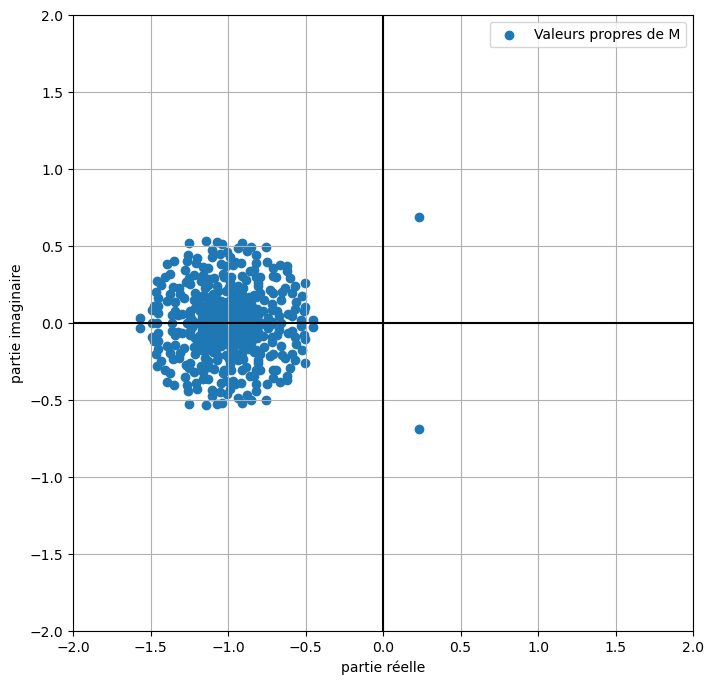

In [49]:
graphique_eigvals_W(V,n)

Spectre du modèle sans $b_iz(t)$ : 

In [50]:
#Relu
def M_bis(D_n,W,g,n):
    return - np.eye(n) + g * W @ D_n
"""
#tanh
def M_bis(W,g,n):
    return - np.eye(n) + g * W
"""

'\n#tanh\ndef M_bis(W,g,n):\n    return - np.eye(n) + g * W\n'

In [51]:
M_b = M_bis(D_n, W,g,n)

In [52]:
V_b = valeurs_propres(M_b)

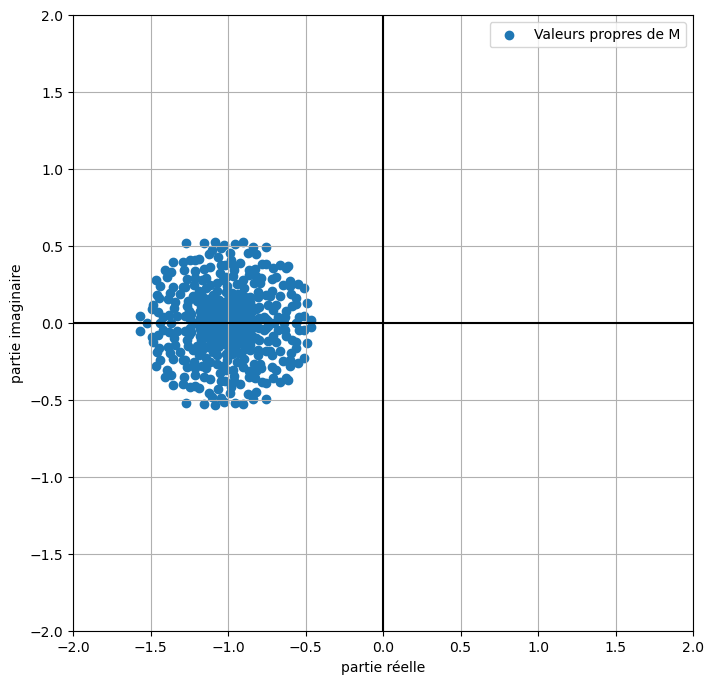

In [53]:
graphique_eigvals_W(V_b,n)